In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import spatialdata as sd
import squidpy as sq
import scanpy as sc
import zarr
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from scipy.stats import median_abs_deviation

In [4]:
zarr.config.set({"array.rectilinear_chunks": True})

In [5]:
sc.set_figure_params(frameon=False)
sc.settings.verbosity = 2
plt.rcParams["axes.grid"] = False

In [6]:
zarr_path = "breast_data/xenium_breast.zarr"

In [7]:
sdata = sd.read_zarr(zarr_path)

In [8]:
sdata

SpatialData object, with associated Zarr store: /home/cenk/Withnell_spice/breast_data/xenium_breast.zarr
├── Images
│     ├── 'he_image': DataTree[cyx] (3, 37433, 57382), (3, 18716, 28691), (3, 9358, 14345), (3, 4679, 7172), (3, 2339, 3586)
│     └── 'morphology_focus': DataTree[cyx] (4, 74945, 51265), (4, 37472, 25632), (4, 18736, 12816), (4, 9368, 6408), (4, 4684, 3204)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (74945, 51265), (37472, 25632), (18736, 12816), (9368, 6408), (4684, 3204)
│     └── 'nucleus_labels': DataTree[yx] (74945, 51265), (37472, 25632), (18736, 12816), (9368, 6408), (4684, 3204)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (699110, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (701534, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (699110, 5101)
with coordinate systems:
    ▸ 'global', with elements:
        he_image (Images), mor

In [9]:
adata = sdata.tables["table"]
adata

AnnData object with n_obs × n_vars = 699110 × 5101
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

In [10]:
adata.var_names_make_unique()

In [11]:
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=[20], log1p=True)

In [12]:
adata.obs["nucleus_ratio"] = adata.obs["nucleus_area"] / adata.obs["cell_area"]

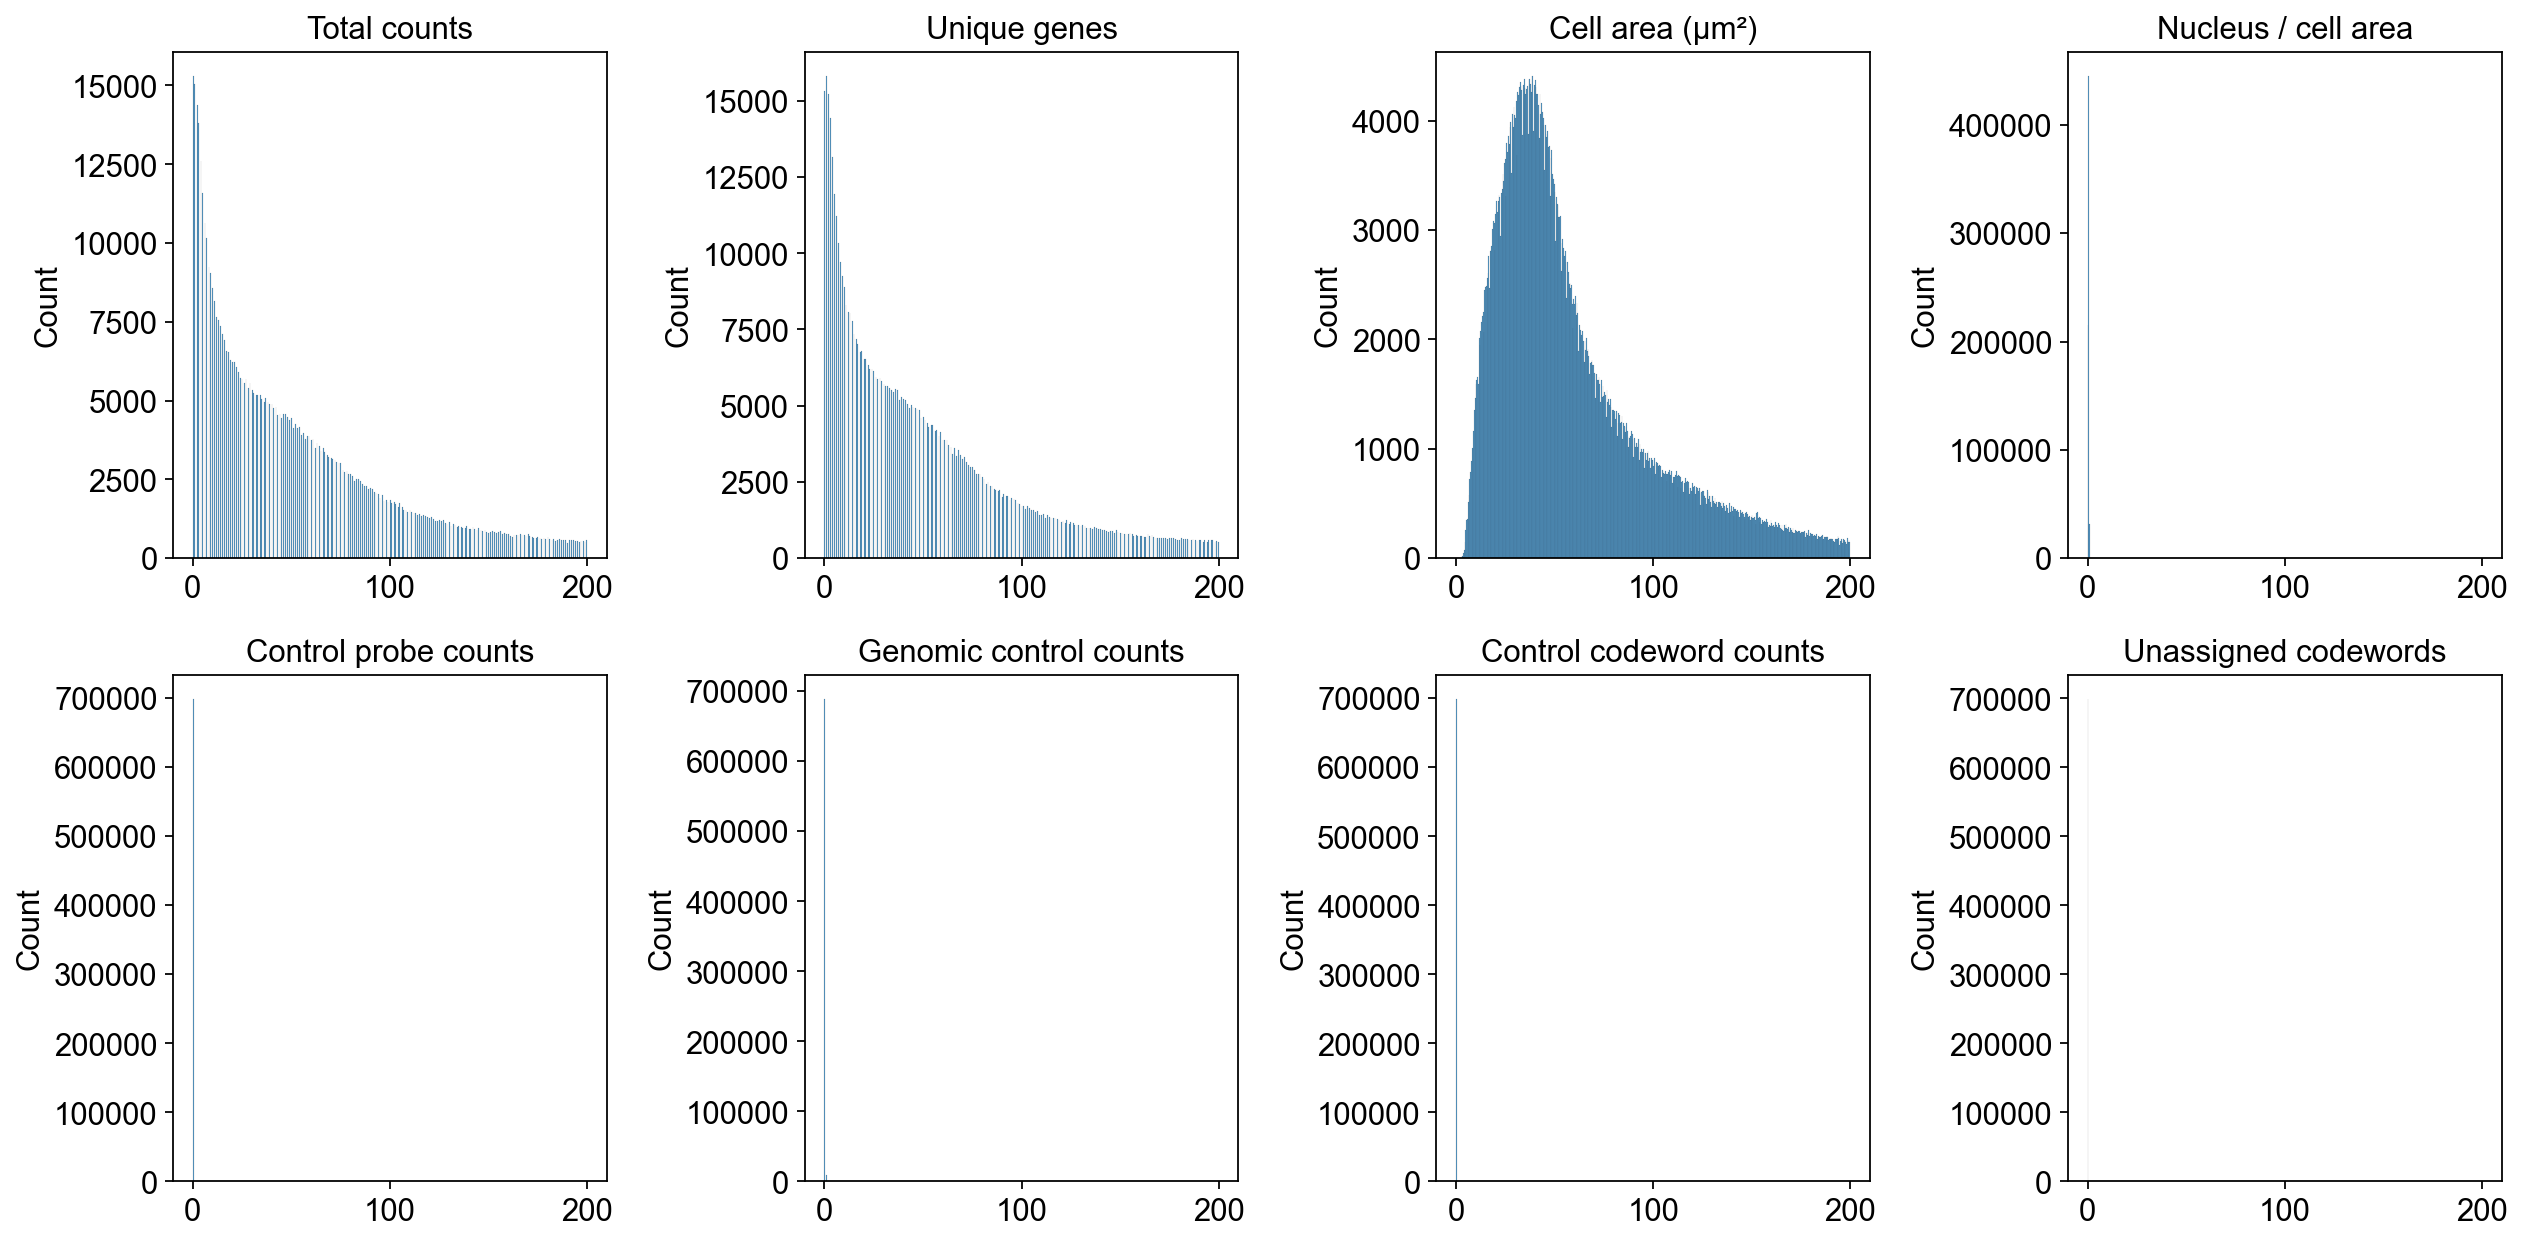

In [13]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8))

pre_qc_panels = [
    ("total_counts",             "Total counts"),
    ("n_genes_by_counts",        "Unique genes"),
    ("cell_area",                "Cell area (µm²)"),
    ("nucleus_ratio",            "Nucleus / cell area"),
    ("control_probe_counts",     "Control probe counts"),
    ("genomic_control_counts",   "Genomic control counts"),
    ("control_codeword_counts",  "Control codeword counts"),
    ("unassigned_codeword_counts","Unassigned codewords"),
]
for ax, (metric, title) in zip(axs.flat, pre_qc_panels):
    sns.histplot(adata.obs[metric], bins=500, kde=False, ax=ax, binrange=(0, 200))
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()

In [14]:
print("Nucleus count per cell:")
print(adata.obs["nucleus_count"].value_counts().sort_index().to_string())

Nucleus count per cell:
nucleus_count
0.0      6926
1.0    683829
2.0      7497
3.0       747
4.0        87
5.0        22
6.0         2


In [15]:
def is_outlier(adata, metric: str, nmads: int, upper_only: bool = False):
    M = adata.obs[metric]
    mad = median_abs_deviation(M)
    if upper_only:
        return M > np.median(M) + nmads * mad
    return (M < np.median(M) - nmads * mad) | (M > np.median(M) + nmads * mad)

In [16]:
flags = {
    "low/high counts":        is_outlier(adata, "log1p_total_counts", nmads=5),
    "low/high genes":         is_outlier(adata, "log1p_n_genes_by_counts", nmads=5),
    "high pct top-20 genes":  is_outlier(adata, "pct_counts_in_top_20_genes", nmads=5),
    "cell area":              is_outlier(adata, "cell_area", nmads=5),
    "control probes":         is_outlier(adata, "control_probe_counts", nmads=3, upper_only=True),
    "genomic control":        is_outlier(adata, "genomic_control_counts", nmads=3, upper_only=True),
    "no nucleus":             (adata.obs["nucleus_count"] == 0),
}

adata.obs["outlier"] = np.logical_or.reduce(list(flags.values()))

for name, flag in flags.items():
    print(f"  {name}: {flag.sum():>7,}")
print(f"\n  total outliers (union): {adata.obs['outlier'].sum():>7,} / {adata.n_obs:,}")

  low/high counts:       0
  low/high genes:       0
  high pct top-20 genes:       0
  cell area:  46,218
  control probes:     798
  genomic control:  10,317
  no nucleus:   6,926

  total outliers (union):  61,185 / 699,110


In [17]:
print(f"Cells before QC: {adata.n_obs:,}")
adata = adata[~adata.obs["outlier"]].copy()

Cells before QC: 699,110


In [18]:
# Calculate 98th percentile threshold
thres = np.quantile(adata.obs["total_counts"], 0.98)

# Subset cells
adata = adata[(adata.obs["total_counts"] >= 25) & (adata.obs["total_counts"] <= thres)].copy()

In [19]:
sc.pp.filter_genes(adata, min_cells=20)

filtered out 6 genes that are detected in less than 20 cells


In [20]:
print(f"Cells after QC:  {adata.n_obs:,}  ({adata.n_obs / 699110 * 100:.1f}% retained)")

Cells after QC:  406,731  (58.2% retained)


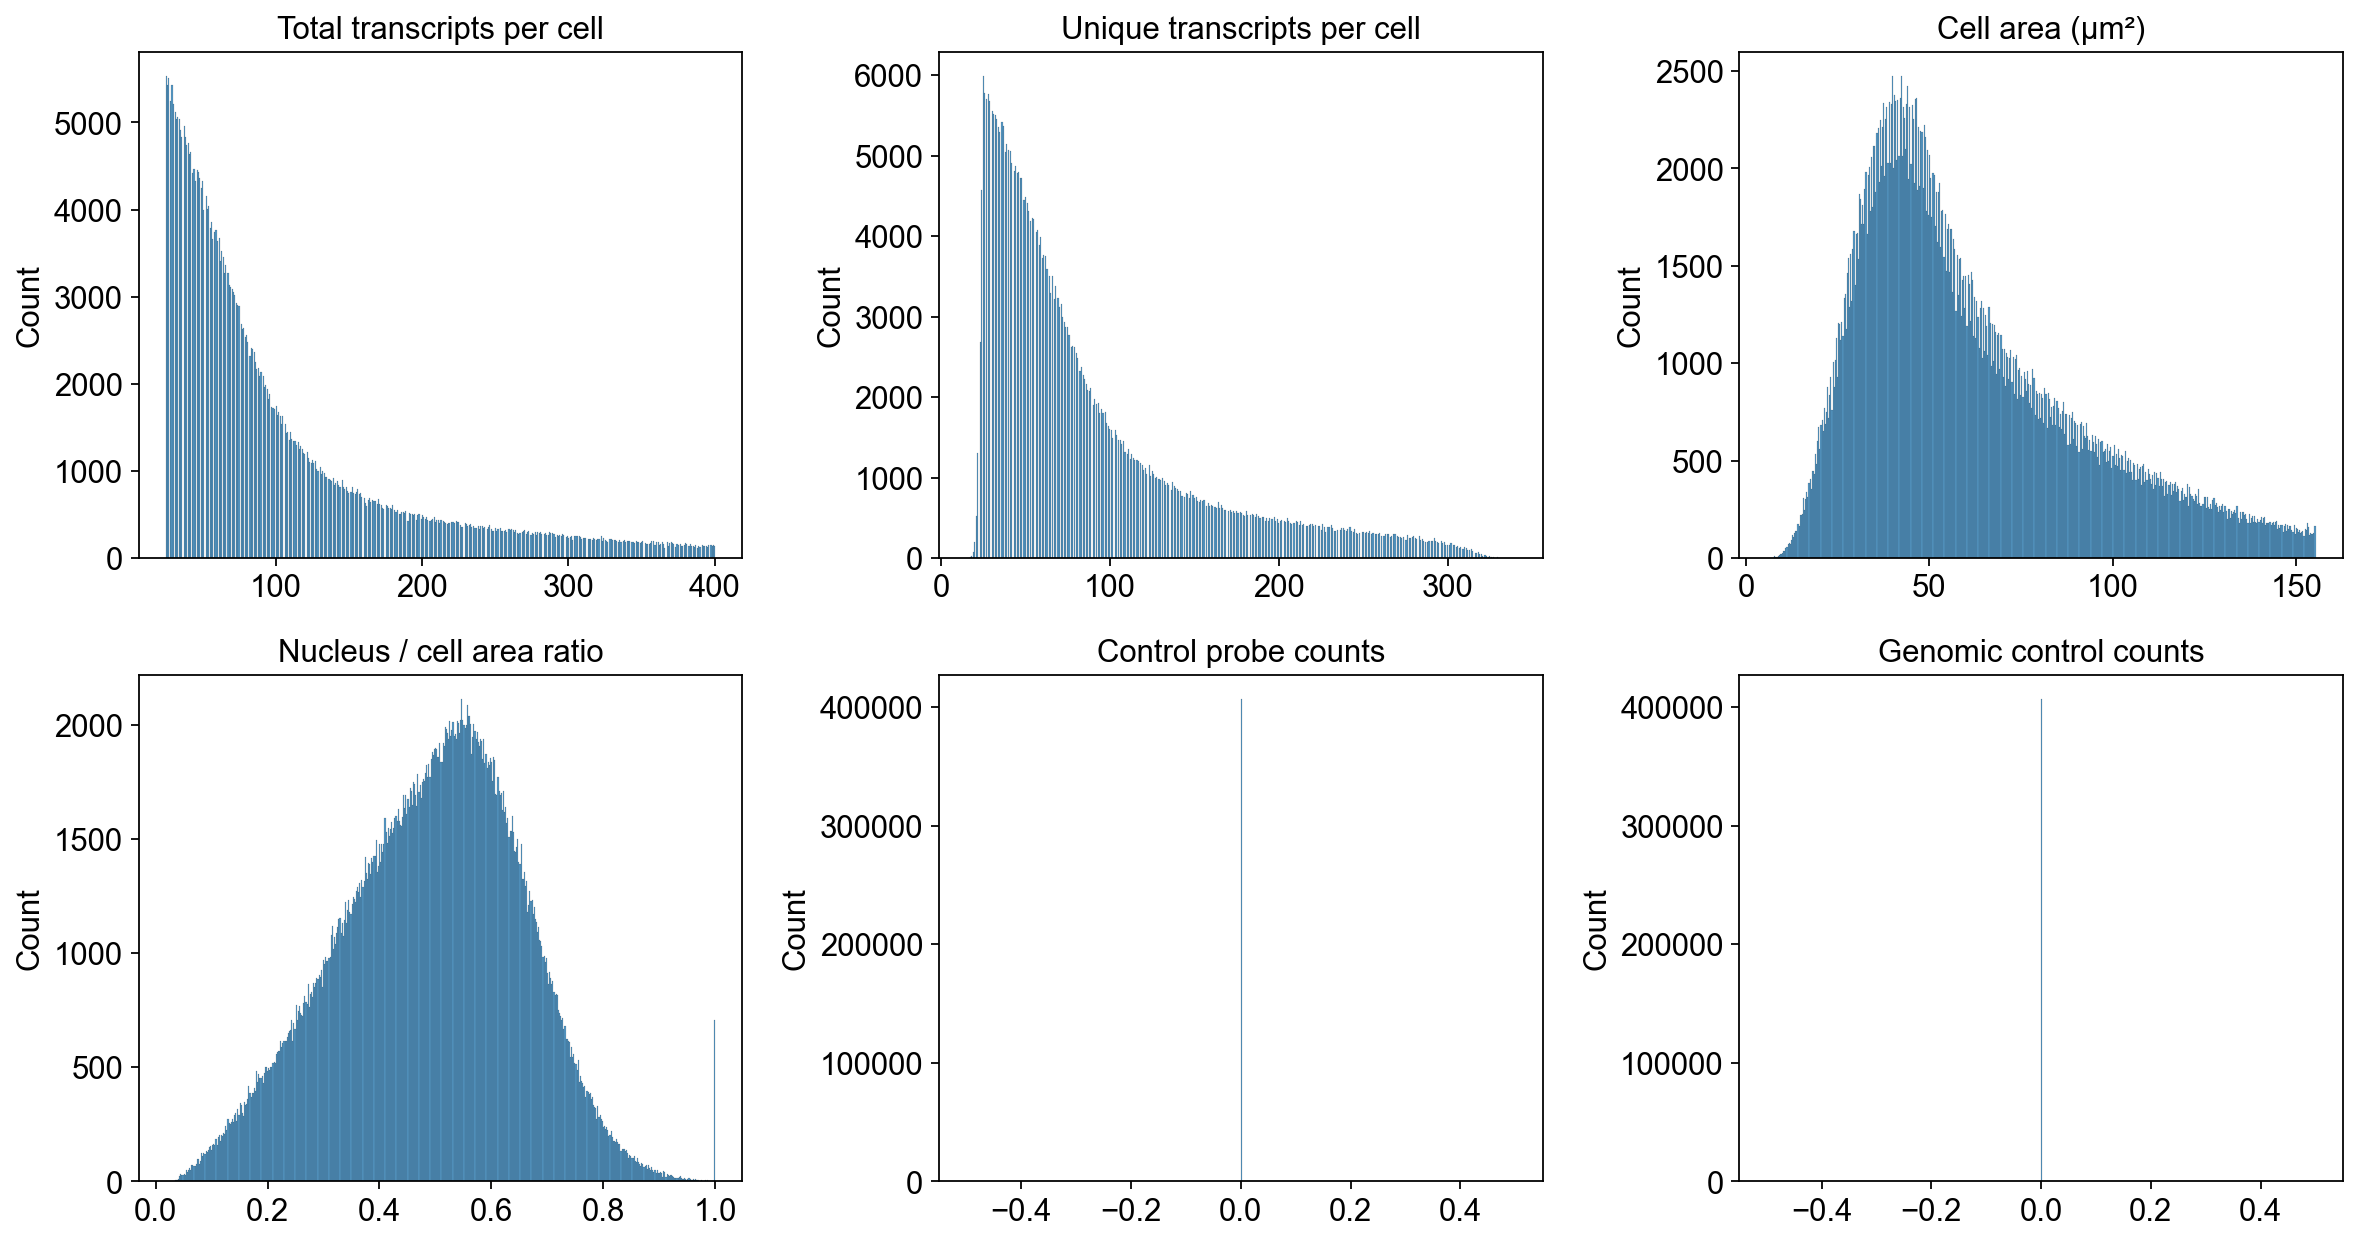

In [21]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))

post_qc_panels = [
    ("total_counts",           "Total transcripts per cell"),
    ("n_genes_by_counts",      "Unique transcripts per cell"),
    ("cell_area",              "Cell area (µm²)"),
    ("nucleus_ratio",          "Nucleus / cell area ratio"),
    ("control_probe_counts",   "Control probe counts"),
    ("genomic_control_counts", "Genomic control counts"),
]
for ax, (metric, title) in zip(axs.flat, post_qc_panels):
    sns.histplot(adata.obs[metric], bins=500, kde=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()

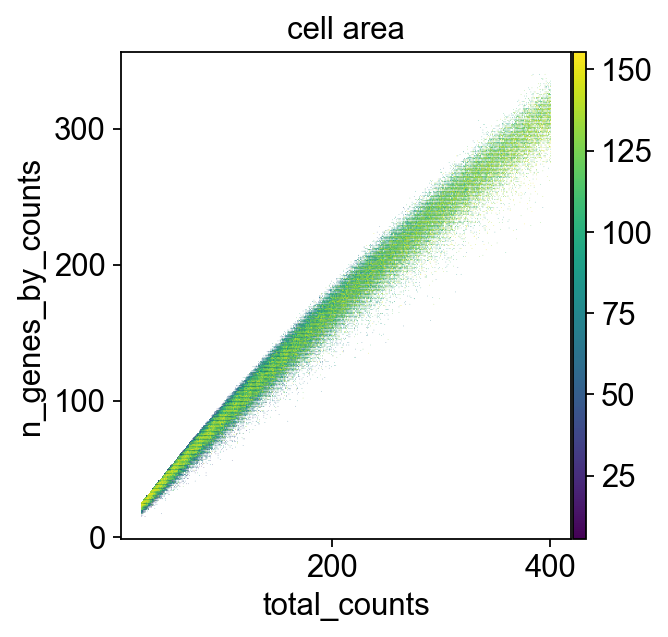

In [22]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="cell_area")

In [23]:
adata.layers["counts"] = adata.X.copy()

In [24]:
sc.pp.normalize_total(adata, target_sum=np.median(adata.obs["total_counts"]))
sc.pp.log1p(adata)

normalizing counts per cell
    finished (0:00:00)


In [25]:
adata.layers["log1p_norm"] = adata.X.copy()

In [26]:
sc.pp.highly_variable_genes(adata, layer="log1p_norm", n_top_genes=2000, flavor="seurat_v3")
adata.var["highly_variable"].value_counts()

extracting highly variable genes


highly_variable
False    3095
True     2000
Name: count, dtype: int64

In [27]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

In [28]:
# sc.pp.regress_out(adata, ["total_counts"], layer="log1p_norm", n_jobs=10)
sc.pp.scale(adata_hvg)

computing PCA
    with n_comps=50
    finished (0:00:04)


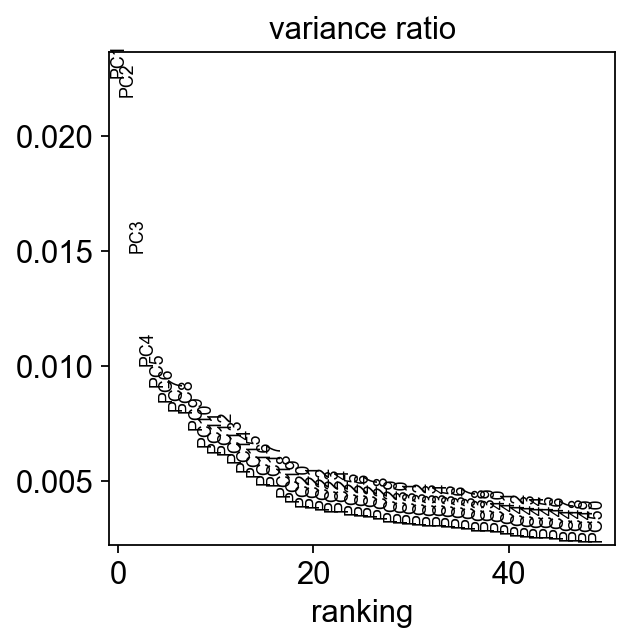

In [29]:
sc.pp.pca(adata_hvg, layer="log1p_norm")
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50)

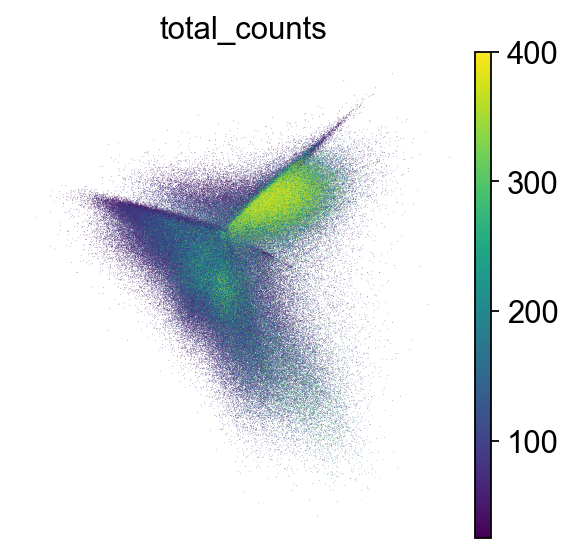

In [30]:
sc.pl.pca(adata_hvg, color="total_counts")

In [31]:
adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]

In [32]:
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30)

computing neighbors


    using 'X_pca' with n_pcs = 20
    finished (0:01:42)


In [33]:
sc.tl.umap(adata)

computing UMAP
    finished (0:09:00)


In [34]:
sc.tl.leiden(adata, resolution=0.4, flavor="igraph")
print("Number of clusters: ", adata.obs["leiden"].nunique())

running Leiden clustering
    finished (0:06:08)
Number of clusters:  26


In [35]:
if "leiden_colors" in adata.uns:
    adata.uns.pop("leiden_colors")

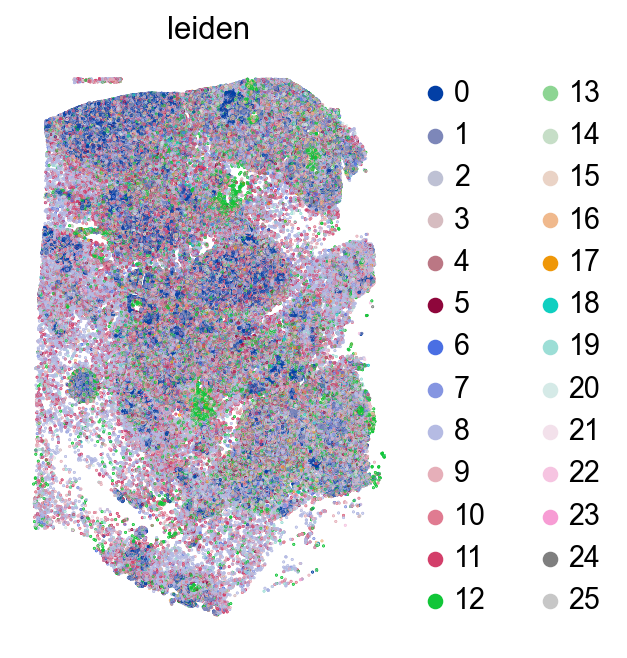

In [36]:
sq.pl.spatial_scatter(
    adata,
    shape=None,
    color="leiden",
)

## Pseudobulk DEG Analysis (PyDESeq2, Leiden clusters, one-vs-rest)

In [37]:
import numpy as np
import pandas as pd
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

In [38]:
N_REPLICATES = 3
np.random.seed(0)

counts_matrix = adata.layers["counts"]  # raw integer counts, cells x genes
leiden_labels = adata.obs["leiden"].values
clusters = adata.obs["leiden"].cat.categories.tolist()

print(f"Leiden clusters: {clusters}")
print(f"Running 1-vs-rest pseudobulk DEG with {N_REPLICATES} pseudoreplicates each")

Leiden clusters: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25']
Running 1-vs-rest pseudobulk DEG with 3 pseudoreplicates each


In [39]:
all_results = {}
inference = DefaultInference(n_cpus=8)

for cluster in clusters:
    print(f"\n--- Cluster {cluster} ---")

    cluster_idx = np.where(leiden_labels == cluster)[0]
    rest_idx    = np.where(leiden_labels != cluster)[0]

    # Assign each cell to one of N_REPLICATES pseudoreplicates
    cluster_reps = np.random.choice(N_REPLICATES, size=len(cluster_idx))
    rest_reps    = np.random.choice(N_REPLICATES, size=len(rest_idx))

    rows, meta = [], []
    for rep in range(N_REPLICATES):
        for grp, idx_all, rep_arr, label in [
            ("cluster", cluster_idx, cluster_reps, "cluster"),
            ("rest",    rest_idx,    rest_reps,    "rest"),
        ]:
            idx = idx_all[rep_arr == rep]
            if len(idx):
                vec = np.asarray(counts_matrix[idx].sum(axis=0)).flatten()
            else:
                vec = np.zeros(adata.n_vars, dtype=float)
            rows.append(vec)
            meta.append({"condition": label, "replicate": rep})

    pseudobulk_df = pd.DataFrame(
        np.array(rows, dtype=np.int64),
        columns=adata.var_names,
    )
    metadata_df = pd.DataFrame(meta)
    metadata_df.index = pseudobulk_df.index.astype(str)
    pseudobulk_df.index = metadata_df.index

    # Drop genes with fewer than 10 summed counts across all pseudo-samples
    keep = pseudobulk_df.sum(axis=0) >= 10
    pseudobulk_df = pseudobulk_df.loc[:, keep]
    print(f"  cells: cluster={len(cluster_idx):,}  rest={len(rest_idx):,}  genes kept: {keep.sum()}")

    try:
        dds = DeseqDataSet(
            counts=pseudobulk_df,
            metadata=metadata_df,
            design_factors="condition",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stat_res = DeseqStats(
            dds,
            contrast=["condition", "cluster", "rest"],
            inference=inference,
            quiet=True,
        )
        stat_res.summary()
        results = stat_res.results_df.dropna(subset=["padj"]).sort_values("padj")
        all_results[cluster] = results
        n_sig = (results["padj"] < 0.05).sum()
        print(f"  significant DEGs (padj<0.05): {n_sig}")
    except Exception as e:
        print(f"  ERROR: {e}")
        all_results[cluster] = pd.DataFrame()

print("\nDone.")


--- Cluster 0 ---
  cells: cluster=37,021  rest=369,710  genes kept: 5095
  significant DEGs (padj<0.05): 3989

--- Cluster 1 ---
  cells: cluster=28,628  rest=378,103  genes kept: 5095
  significant DEGs (padj<0.05): 3852

--- Cluster 2 ---
  cells: cluster=7,248  rest=399,483  genes kept: 5095
  significant DEGs (padj<0.05): 2814

--- Cluster 3 ---
  cells: cluster=26,416  rest=380,315  genes kept: 5095
  significant DEGs (padj<0.05): 3258

--- Cluster 4 ---
  cells: cluster=39,240  rest=367,491  genes kept: 5095
  significant DEGs (padj<0.05): 3477

--- Cluster 5 ---
  cells: cluster=11,896  rest=394,835  genes kept: 5095
  significant DEGs (padj<0.05): 2561

--- Cluster 6 ---
  cells: cluster=20,311  rest=386,420  genes kept: 5095
  significant DEGs (padj<0.05): 2839

--- Cluster 7 ---
  cells: cluster=18,606  rest=388,125  genes kept: 5095


  significant DEGs (padj<0.05): 2458

--- Cluster 8 ---
  cells: cluster=67,251  rest=339,480  genes kept: 5095
  significant DEGs (padj<0.05): 3538

--- Cluster 9 ---
  cells: cluster=12,650  rest=394,081  genes kept: 5095
  significant DEGs (padj<0.05): 2393

--- Cluster 10 ---
  cells: cluster=20,045  rest=386,686  genes kept: 5095
  significant DEGs (padj<0.05): 3025

--- Cluster 11 ---
  cells: cluster=30,578  rest=376,153  genes kept: 5095
  significant DEGs (padj<0.05): 3091

--- Cluster 12 ---
  cells: cluster=26,589  rest=380,142  genes kept: 5095
  significant DEGs (padj<0.05): 3012

--- Cluster 13 ---
  cells: cluster=7,354  rest=399,377  genes kept: 5095
  significant DEGs (padj<0.05): 2062

--- Cluster 14 ---
  cells: cluster=3,790  rest=402,941  genes kept: 5095
  significant DEGs (padj<0.05): 1516

--- Cluster 15 ---
  cells: cluster=2,010  rest=404,721  genes kept: 5095
  significant DEGs (padj<0.05): 1180

--- Cluster 16 ---
  cells: cluster=11,895  rest=394,836  genes

In [40]:
# Top 5 upregulated markers per cluster (by log2FC, padj < 0.01)
top_markers = {}
for cluster, res in all_results.items():
    if res.empty:
        top_markers[cluster] = []
        continue
    sig_up = res[(res["log2FoldChange"] > 1.5) & (res["padj"] < 0.05)]
    sig_up = sig_up.sort_values("log2FoldChange", ascending=False)
    top_markers[cluster] = sig_up.head(5).index.tolist()

for c, genes in top_markers.items():
    print(f"Cluster {c}: {genes}")

Cluster 0: ['LRP2', 'CRH', 'PPFIA4', 'SIM2', 'WNT9A']
Cluster 1: ['BMPR1B', 'NAT1', 'KCNF1', 'MAL2', 'IGSF1']
Cluster 2: ['PEG10', 'LRP2', 'CYP4B1', 'CTNND2', 'XBP1']
Cluster 3: ['TRAC', 'TRBC1', 'FOXP3', 'CTLA4', 'CCR8']
Cluster 4: ['IL7R', 'TRBC1', 'TRAC', 'CD6', 'KLRB1']
Cluster 5: ['CD52', 'MS4A1', 'BLK', 'TNFRSF13B', 'CD19']
Cluster 6: ['HDC', 'IL1RL1', 'CTSG', 'BIRC3', 'KIT']
Cluster 7: ['MZB1', 'POU2AF1', 'DERL3', 'CD38', 'NR0B1']
Cluster 8: ['POSTN', 'CCN2', 'MEG3', 'TNC', 'SERPINE1']
Cluster 9: ['CLEC14A', 'PLVAP', 'ADGRL4', 'KDR', 'PCDH17']
Cluster 10: ['SLCO2A1', 'SELP', 'AQP1', 'PLVAP', 'ADGRL4']
Cluster 11: ['CD300E', 'ITGAX', 'C5AR1', 'IL1B', 'FCN1']
Cluster 12: ['USP9Y', 'FCRL1', 'MPZ', 'BLK', 'MS4A1']
Cluster 13: ['IL7R', 'THEMIS', 'TCF7', 'ZAP70', 'STAT4']
Cluster 14: ['TRAC', 'CTLA4', 'FOXP3', 'TIGIT', 'BCL11B']
Cluster 15: ['CXCR4', 'IL7R', 'GZMK', 'CD8A', 'NCR1']
Cluster 16: ['RAB11FIP1', 'IGSF1', 'GABRP', 'ZDHHC22', 'SEZ6L']
Cluster 17: ['TRBC1', 'GZMK', 'GZMA', 'G

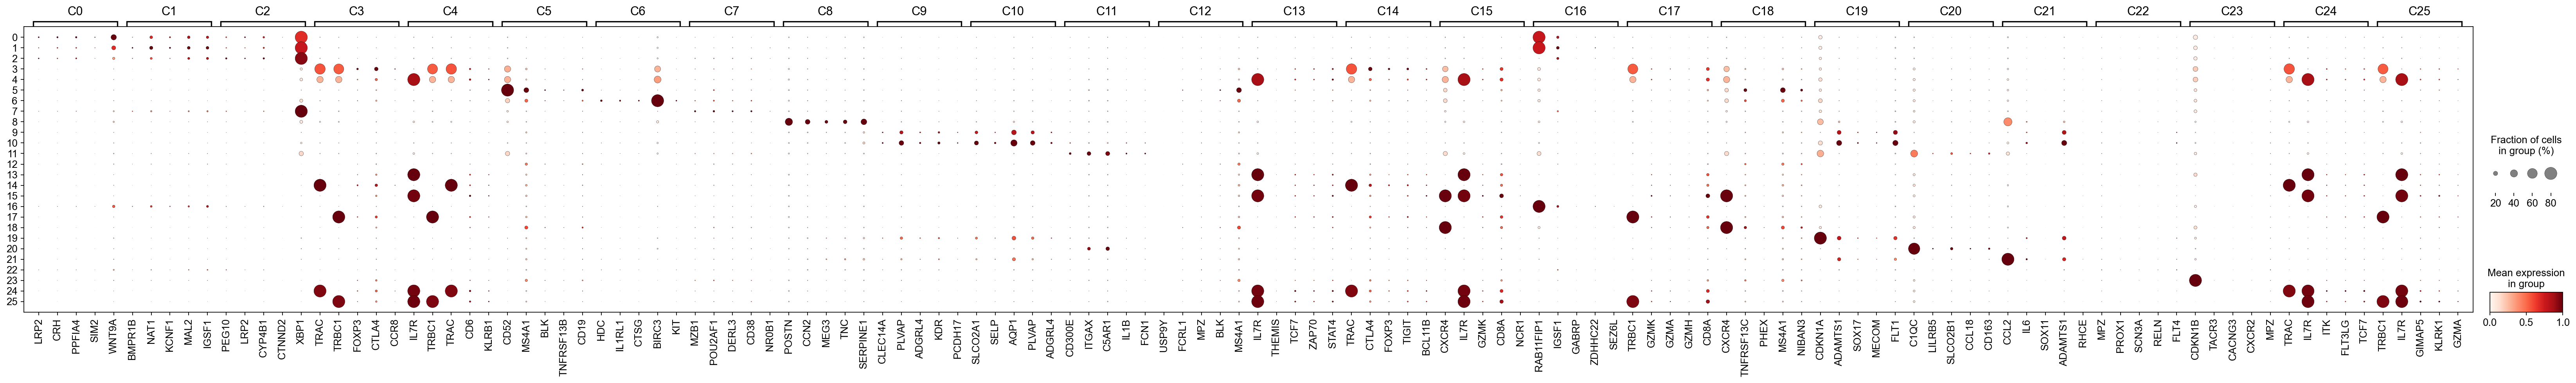

In [41]:
# Build ordered var_names dict: cluster label -> gene list (skip empty clusters)
marker_dict = {
    f"C{c}": genes
    for c, genes in top_markers.items()
    if genes
}

sc.pl.dotplot(
    adata,
    var_names=marker_dict,
    groupby="leiden",
    standard_scale="var",
    dot_max=0.8,
    figsize=(max(12, len(marker_dict) * 2), 6),
    show=True,
    save="breast_top5_markers.pdf",
)

In [42]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon", layer="log1p_norm")

ranking genes
    finished (0:01:36)


    using 'X_pca' with n_pcs = 20
Storing dendrogram info using `.uns['dendrogram_leiden']`


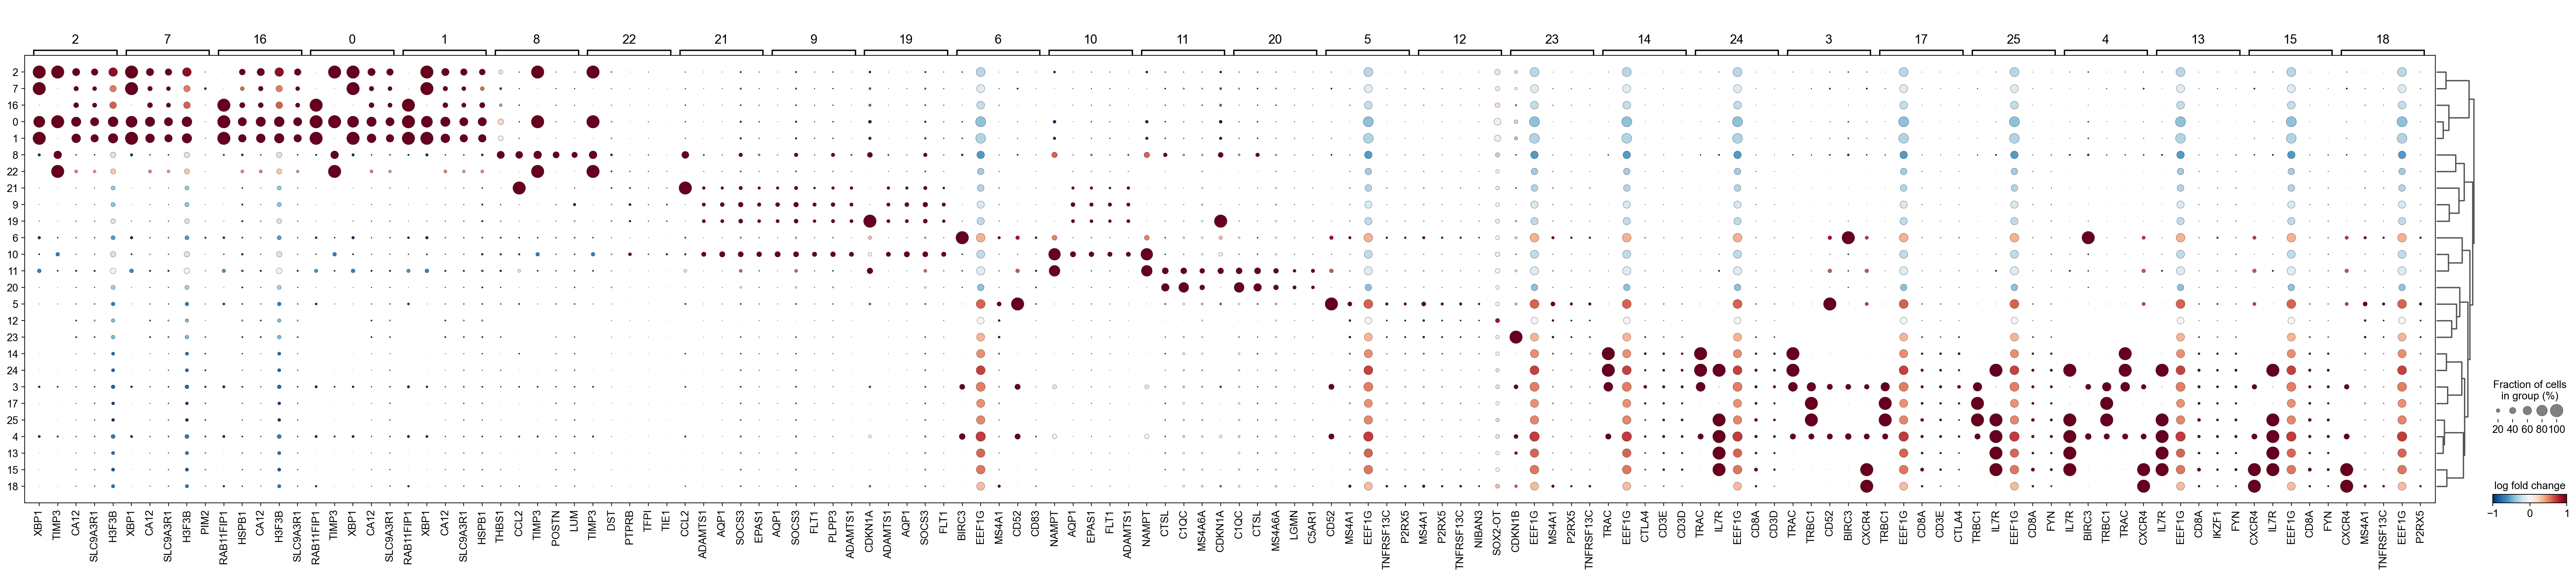

In [43]:
sc.tl.dendrogram(adata, groupby="leiden", n_pcs=20)
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden",
    n_genes=5,
    cmap="RdBu_r",
    values_to_plot="logfoldchanges",
    vmin=-1,
    vmax=1,
)

In [44]:
# get top 10 gene expression for each leiden cluster
degs = sc.get.rank_genes_groups_df(adata, group=None)
degs = degs.groupby("group").head(10)
degs

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,RAB11FIP1,262.806854,3.012609,0.000000e+00,0.000000
1,0,TIMP3,251.114883,2.587916,0.000000e+00,0.000000
2,0,XBP1,204.135391,2.335254,0.000000e+00,0.000000
3,0,CA12,179.387848,2.611129,0.000000e+00,0.000000
4,0,SLC9A3R1,146.725128,2.223369,0.000000e+00,0.000000
...,...,...,...,...,...,...
127380,25,CD3D,5.396192,1.846635,6.807011e-08,0.000008
127381,25,CD3E,5.288774,1.736500,1.231389e-07,0.000014
127382,25,SMCHD1,5.072859,1.430591,3.918823e-07,0.000040
127383,25,IKZF1,4.744972,1.542004,2.085349e-06,0.000180


In [45]:
annotation_dict = {
    "0": "Tumour cell",
    "1": "Tumour cell",
    "2": "Tumour cell",
    "3": "Regulatory T cell",
    "4": "CD4+ T cell",
    "5": "B cell",
    "6": "Mast cell",
    "7": "Plasma cell",
    "8": "Cancer-associated fibroblast",
    "9": "Endothelial",
    "10": "Endothelial",
    "11": "Inflammatory myeloid",
    "12": "B cell",
    "13": "CD4+ T cell",
    "14": "Regulatory T cell",
    "15": "CD8+ T cell",
    "16": "Tumour cell",
    "17": "Activated CD8+ T cell",
    "18": "B cell",
    "19": "Endothelial",
    "20": "C1QC+ macrophage",
    "21": "Inflammatory stromal",
    "22": "Lymphatic endothelial",
    "23": "Neural-like stromal",
    "24": "Memory T cell",
    "25": "CD8+ T cell",
}

In [46]:
adata.obs["cell_type"] = [annotation_dict[cluster] for cluster in adata.obs["leiden"]]
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

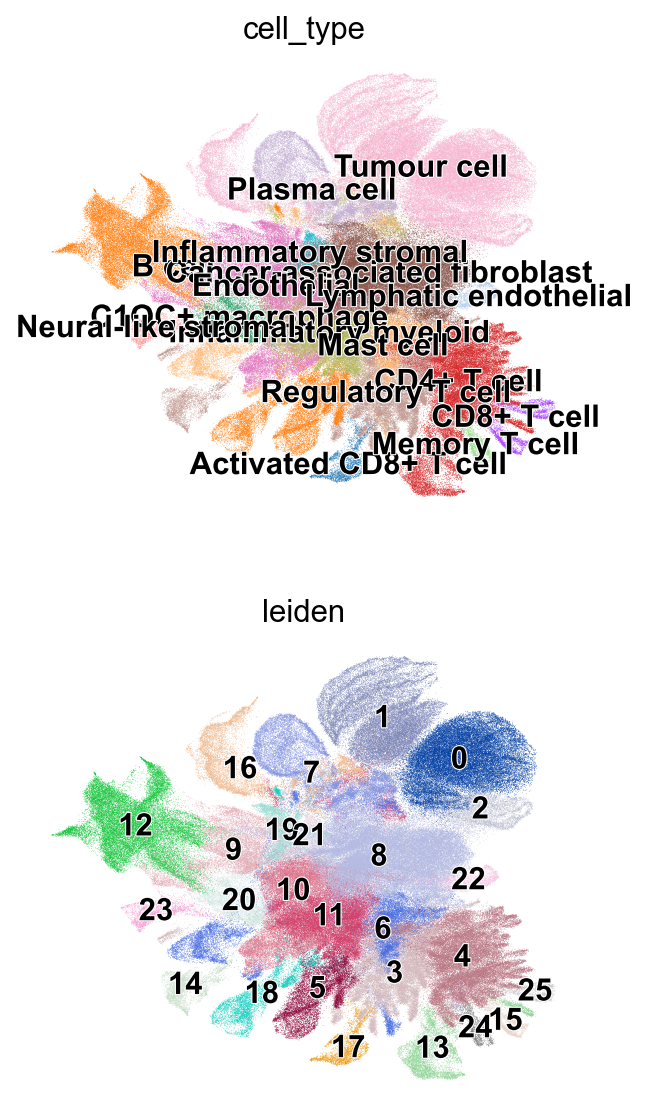

In [47]:
sc.pl.umap(
    adata=adata,
    color=["cell_type", "leiden"],
    ncols=1,
    legend_loc="on data",
    legend_fontoutline=1,
)

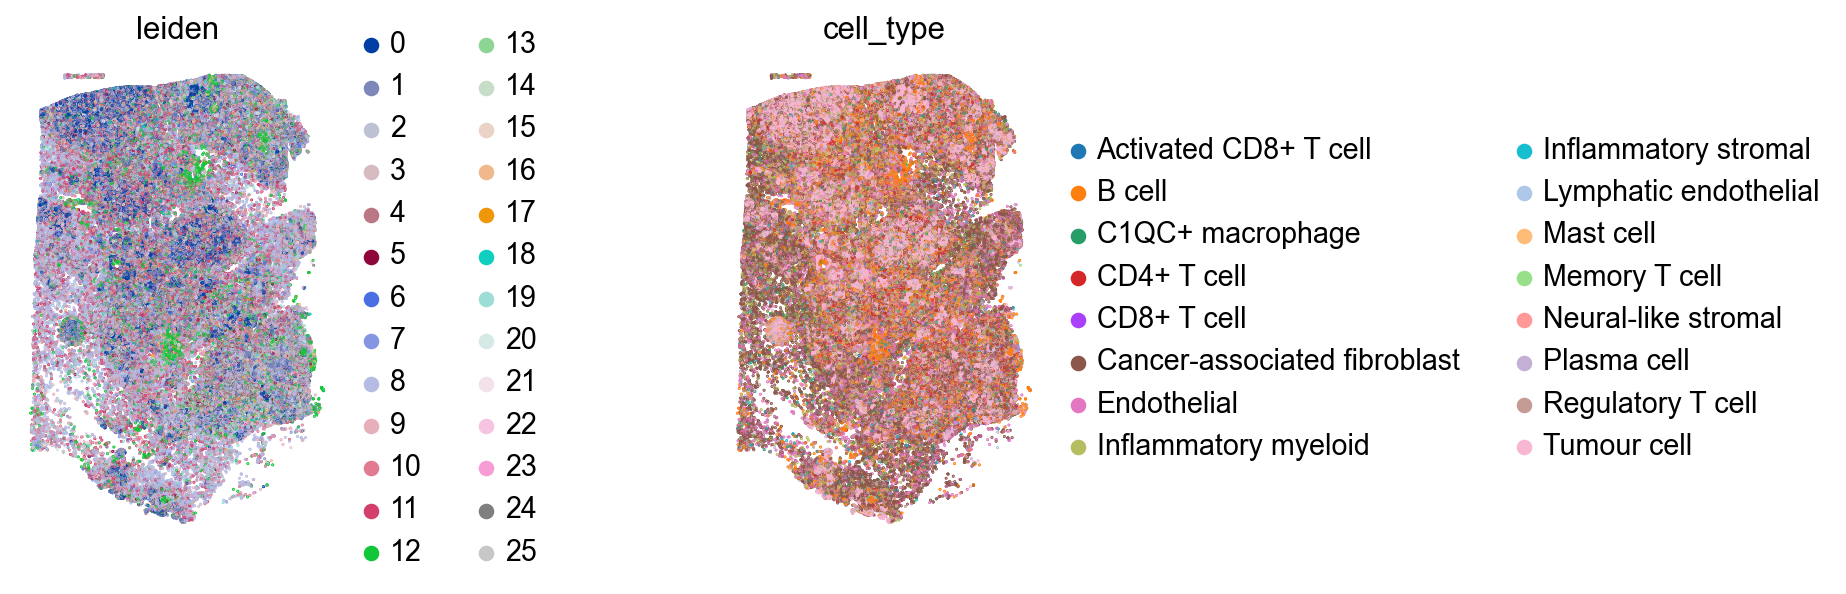

In [48]:
sq.pl.spatial_scatter(adata, color=["leiden", "cell_type"], wspace=0.25, shape=None)

In [49]:
adata.write_h5ad("processed_data/xenium_breast_annotated.h5ad")